# Recommendation, PCA and K-means analysis
Distinguish descriptive structure from recommendation relevance. This notebook inspects an actually executed, explicitly exploratory MLflow run; it never reports unexecuted temporal or transfer validation as passed.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside the project')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/tfm-matplotlib')
os.environ.setdefault('XDG_CACHE_HOME', '/tmp/tfm-cache')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src.config import ROOT, MODELS_DIR
from src.preprocessing.clean import load_players
players = load_players()
dataset = json.loads((ROOT / 'reports/dataset.json').read_text())
display(Markdown('**Dataset:** ' + dataset['dataset_kind'] + '. Legacy-labelled observations are preliminary; no synthetic rows are included.'))
assert not players.source.str.contains('demo|synthetic', case=False).any()

from src.models.recommend import PlayerRecommender
rec=PlayerRecommender.load()
meta=json.loads((MODELS_DIR/'metrics.json').read_text())
display(meta)


**Dataset:** real_legacy_unverified. Legacy-labelled observations are preliminary; no synthetic rows are included.

{'feature_cols': ['gls_p90', 'ast_p90'],
 'metrics': {'silhouette_kmeans': 0.4387664231563881,
  'pca_explained_variance_sum': 1.0,
  'mean_top10_jaccard_overlap': 0.0,
  'cluster_seed_ari_mean': 0.9056938561818292},
 'model_path': 'models/real/recommender.joblib',
 'dataset': {'dataset_kind': 'real_legacy_unverified',
  'rows': 420,
  'sources': ['fbref_cache'],
  'snapshots': ['0d1f16e60c2116c4e6a3cefd468932effcc5d21fa527e1639d79ca551f909003'],
  'dataset_sha256': '05e6266ab5f45651ff69c763413d3fbb196de6fd061d44bb48899b09b305fc6c',
  'limitations': ['Legacy retrieval date and original HTML absent; ancillary stats discarded']},
 'git_commit': '602f883bae3ee6feadfea2c51cab551ec619692b',
 'git_dirty': False,
 'git_dirty_scope': 'source_and_dependencies',
 'run_id': '7931521312e34ea981241165f423977c',
 'evaluation_scope': 'descriptive exploratory; no transfer or future-performance claims',
 'temporal_status': 'blocked: fewer than two comparable consecutive seasons'}

In [2]:
from src.data.provenance import sha256
assert sha256(ROOT/'data/processed/real/players.parquet') == meta['dataset']['dataset_sha256']
print('Git commit:', meta['git_commit'], 'Dirty:',meta['git_dirty'])
print('Run ID:', meta['run_id'])
print('Fitted features:',rec.artifacts.feature_cols)
display(pd.read_csv(ROOT/'reports/experiments/baselines.csv'))


Git commit: 602f883bae3ee6feadfea2c51cab551ec619692b Dirty: False
Run ID: 7931521312e34ea981241165f423977c
Fitted features: ['gls_p90', 'ast_p90']


,style,measured_weight_fraction,status,overlap_linear_weighted,overlap_minutes,overlap_goals_assists
0,posesion,0.30,unsupported_missing_statistics,NaN,NaN,NaN
1,presion_alta,0.10,unsupported_missing_statistics,NaN,NaN,NaN
2,vertical,0.35,unsupported_missing_statistics,NaN,NaN,NaN
3,contraataque,0.40,unsupported_missing_statistics,NaN,NaN,NaN
4,solidez_defensiva,0.10,unsupported_missing_statistics,NaN,NaN,NaN
5,desborde_banda,0.30,unsupported_missing_statistics,NaN,NaN,NaN
6,finisher,1.00,supported_descriptive,0.111111,0.0,0.0
7,creator,1.00,supported_descriptive,0.111111,0.0,0.0


## Baselines and ranking interpretation
Compare cosine style-direction rankings with linear weighted standardized scores, goals+assists per 90, and minutes played. Top-k Jaccard overlap describes ranking agreement, not relevance or transfer success. A separate temporal profile-retrieval benchmark is implemented, including a seeded random baseline, but requires consecutive observed seasons. It tests profile persistence rather than the quality of a signing. Tactical styles below 60% measured absolute weight are disabled rather than inferred from unavailable data.

,train_through,evaluation_season,method,queries,candidate_count,recall_at_5,mrr


**Temporal benchmark:** blocked: fewer than two comparable consecutive seasons

mean       min  max
style    perturbation                               
creator  training_bootstrap  0.668309  0.333333  1.0
         weight_20_percent   1.000000  1.000000  1.0
finisher training_bootstrap  0.656000  0.333333  1.0
         weight_20_percent   1.000000  1.000000  1.0

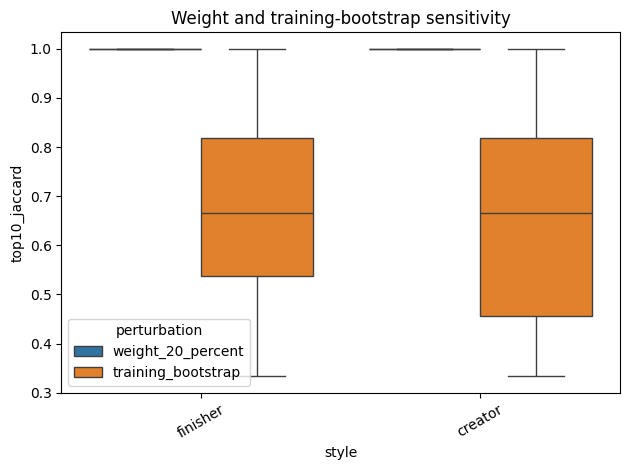

In [3]:
temporal=pd.read_csv(ROOT/'reports/experiments/temporal_proxy.csv')
display(temporal)
display(Markdown('**Temporal benchmark:** '+meta['temporal_status']))
robustness=pd.read_csv(ROOT/'reports/experiments/robustness.csv')
display(robustness.groupby(['style','perturbation']).top10_jaccard.agg(['mean','min','max']))
sns.boxplot(data=robustness,x='style',y='top10_jaccard',hue='perturbation');plt.xticks(rotation=30);plt.title('Weight and training-bootstrap sensitivity');plt.tight_layout();plt.show()


Multiplying a single-feature direction by a positive weight does not change cosine rankings. Stability of the goals-only or assists-only profiles under these perturbations is therefore expected by construction; it is not evidence of robust scouting quality. Thirty bootstrap resamples of the observed training rows also refit medians/scaling and rank the unchanged original candidate set. This gives a more useful preprocessing-sensitivity diagnostic. Full-feature multi-source validation remains required.

,gls_p90,ast_p90
PC1,0.707107,0.707107
PC2,-0.707107,0.707107


PC1    0.654722
PC2    0.345278
Name: explained_variance, dtype: float64

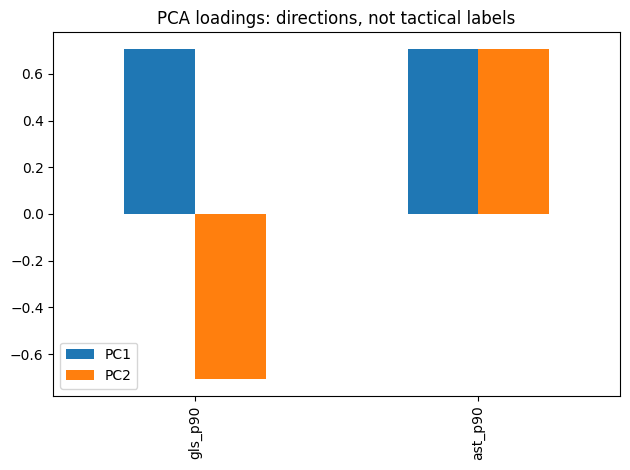

,gls_p90,ast_p90
cluster,,
0,0.068473,0.163271
1,0.156008,0.042019
2,0.014756,0.020207
3,0.709748,0.235895
4,0.419455,0.096895
5,0.161813,0.347660


pos_main,DF,FW,GK,MF
cluster,,,,
0,27,9,0,52
1,23,13,0,42
2,104,2,27,45
3,0,9,0,2
4,0,27,0,14
5,2,4,0,18


,seed,adjusted_rand
0,0,0.956247
1,1,0.803268
2,7,0.963655
3,42,1.000000
4,100,0.805300


In [4]:
loadings=pd.DataFrame(rec.artifacts.pca.components_,columns=rec.artifacts.feature_cols,index=[f'PC{i+1}' for i in range(rec.artifacts.pca.n_components_)])
display(loadings)
display(pd.Series(rec.artifacts.pca.explained_variance_ratio_,index=loadings.index,name='explained_variance'))
loadings.T.plot.bar(title='PCA loadings: directions, not tactical labels');plt.tight_layout();plt.show()
profiles=rec.players.groupby('cluster')[rec.artifacts.feature_cols].mean()
display(profiles)
display(pd.crosstab(rec.players.cluster,rec.players.pos_main))
display(pd.read_csv(ROOT/'reports/experiments/cluster_stability.csv'))


With two retained features and two PCs, explained variance totals 100% by construction. PCA has rotated the feature plane, not demonstrated successful dimensionality reduction. K-means partitions attack-production levels, including a near-zero-output group; these groups must not be labelled playing styles. Silhouette and seed ARI describe cluster geometry and initialization stability, not transfer relevance.

In [5]:
for style in ['finisher','creator']:
    display(Markdown('### '+style))
    top=rec.recommend(style,top_n=5)
    display(top[['player','team','pos','minutes','gls_p90','ast_p90','affinity']])
    print('Median top-5 minutes:', top.minutes.median())


### finisher

,player,team,pos,minutes,gls_p90,ast_p90,affinity
345,Umar Sadiq,Real Sociedad,FW,1077.0,0.250696,0.083565,0.999505
215,Dodi Lukebakio,Sevilla,"MF,FW",1125.0,0.400000,0.080000,0.999361
99,Anastasios Douvikas,Celta Vigo,FW,905.0,0.696133,0.099448,0.999266
52,Ante Budimir,Osasuna,FW,2435.0,0.628337,0.073922,0.999220
369,Jørgen Strand Larsen,Celta Vigo,FW,2863.0,0.408662,0.094307,0.998899


Median top-5 minutes: 1125.0


### creator

,player,team,pos,minutes,gls_p90,ast_p90,affinity
16,Hugo Álvarez,Celta Vigo,"MF,FW",762.0,0.118110,0.118110,0.999989
4,Ilias Akhomach,Villarreal,MF,1511.0,0.119126,0.119126,0.999901
66,William Carvalho,Real Betis,MF,680.0,0.132353,0.397059,0.999631
251,Luka Modrić,Real Madrid,MF,1688.0,0.106635,0.319905,0.999543
299,Carles Pérez,Celta Vigo,MF,772.0,0.116580,0.116580,0.999384


Median top-5 minutes: 772.0


Cosine measures direction after centering: a balanced low-output player and a prolific player can share a direction. Inspect raw rates and minutes next to the ranking and compare the linear baseline. Expert review, position-specific feature availability, uncertainty intervals and historical transfer labels are still needed before operational signing recommendations.